## Analysis extension #3 

This notebook keeps the finalized AE3 biological specification (Qiu annotation + developmental-time definitions) and **recomputes its numerical geometry in the primary clean joint encoder produced by AE1b**.

The biological masks are fixed; the PCA coordinates, centroids, developmental displacement vectors, malignant cosines, bootstrap intervals and nulls are recalculated because retraining changes the embedding coordinate system.

No trunk/ductal state is manufactured, and the old `foregut_other` star is not restored.

(*note that in the notebook last running AE was labeled WP, work_package*)

## 1. Libraries and helper functions

In [8]:
from pathlib import Path
import os, json
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import scanpy as sc
import torch

from sklearn.decomposition import PCA
from transformers import BertForMaskedLM

def centroid(X):
    return np.asarray(X).mean(axis=0)

def centroid_value(X, labels, value):
    labels = np.asarray(labels)
    return np.asarray(X)[labels == value].mean(axis=0)

def unit(v):
    v = np.asarray(v)
    return v / (np.linalg.norm(v) + 1e-12)

def cos_sim(a, b):
    a = np.asarray(a); b = np.asarray(b)
    return np.dot(a, b) / ((np.linalg.norm(a) * np.linalg.norm(b)) + 1e-12)

def angle_deg(a, b):
    return np.degrees(np.arccos(np.clip(cos_sim(a, b), -1, 1)))

def state_centroid(X, mask):
    mask = np.asarray(mask, dtype=bool)
    if mask.sum() == 0:
        raise ValueError("State mask contains zero cells.")
    return np.asarray(X)[mask].mean(axis=0)

def equal_day_centroid(X, obs, mask, day_col="dev_day", min_day_n=3):
    '''
    Equal weight to each represented developmental day rather than to each cell.
    Days represented by fewer than min_day_n cells are excluded from this
    sensitivity centroid and reported.
    '''
    mask = np.asarray(mask, dtype=bool)
    sub = obs.loc[mask].copy()
    days = sorted(pd.unique(sub[day_col].dropna()))
    day_centroids = []
    used = []
    omitted = []

    for d in days:
        local = mask & (obs[day_col].to_numpy() == d)
        n = int(local.sum())
        if n >= min_day_n:
            day_centroids.append(np.asarray(X)[local].mean(axis=0))
            used.append((d, n))
        else:
            omitted.append((d, n))

    if not day_centroids:
        raise ValueError("No developmental days pass min_day_n.")

    return np.vstack(day_centroids).mean(axis=0), used, omitted


## 2. Load the trained MLM and compute CLS embeddings

In [ ]:
DATA_ROOT = Path("/home/jfpoyatos/Work/MNCN_24_25/Development_and_PDAC/data")
AUDITED_ROOT = DATA_ROOT / "revision_audited_mlm"
MANIFEST_PATH = AUDITED_ROOT / "manifest.json"

if not MANIFEST_PATH.exists():
    raise FileNotFoundError(
        f"{MANIFEST_PATH}\nRun AE1b audited retraining first."
    )

with open(MANIFEST_PATH) as f:
    AUDIT_MANIFEST = json.load(f)

PRIMARY_SEED = int(AUDIT_MANIFEST["primary_seed"])
saved_dir = Path(AUDIT_MANIFEST["models"]["joint"][str(PRIMARY_SEED)])
DEV_H5AD = Path(AUDIT_MANIFEST["dev_h5ad"])
CANCER_H5AD = Path(AUDIT_MANIFEST["cancer_h5ad"])
AE3_OUTDIR = AUDITED_ROOT / "analysis" / f"ae3_developmental_reference_joint_seed_{PRIMARY_SEED}"
AE3_OUTDIR.mkdir(parents=True, exist_ok=True)

model = BertForMaskedLM.from_pretrained(saved_dir)

with open(saved_dir / "vocab_meta.json") as f:
    meta = json.load(f)

X_tokens_eval = np.load(saved_dir / "X_tokens.npy")
X_attn_eval   = np.load(saved_dir / "X_attn.npy")
domain_eval   = np.load(saved_dir / "domain.npy")

@torch.no_grad()
def cls_embeddings(model, Xt, At, batch_size=16):
    device = "cuda" if torch.cuda.is_available() else "cpu"
    model.to(device)
    model.eval()
    embs = []
    for i in range(0, Xt.shape[0], batch_size):
        x = torch.as_tensor(Xt[i:i+batch_size], dtype=torch.long, device=device)
        a = torch.as_tensor(At[i:i+batch_size], dtype=torch.long, device=device)
        out = model.bert(
            input_ids=x,
            attention_mask=a,
            output_hidden_states=False,
            return_dict=True
        )
        embs.append(out.last_hidden_state[:, 1, :].cpu())
    return torch.cat(embs, dim=0).numpy()

# Prefer cached definitive embeddings written by AE1b; recompute only if absent.
cache_dev = saved_dir / "X_dev_cls.npy"
cache_can = saved_dir / "X_cancer_cls.npy"

if cache_dev.exists() and cache_can.exists():
    X_dev = np.load(cache_dev)
    X_can = np.load(cache_can)
else:
    CLS = cls_embeddings(model, X_tokens_eval, X_attn_eval, batch_size=16)
    X_dev = CLS[domain_eval == 0]
    X_can = CLS[domain_eval == 1]
    del CLS

print("Primary clean joint seed:", PRIMARY_SEED)
print("X_dev:", X_dev.shape)
print("X_can:", X_can.shape)


Primary clean joint seed: 17
X_dev: (34760, 256)
X_can: (28131, 256)


## 3. Load developmental and cancer metadata; verify row correspondence

In [10]:
A_dev = sc.read_h5ad(DEV_H5AD)
A_can = sc.read_h5ad(CANCER_H5AD)

assert A_dev.n_obs == X_dev.shape[0], (
    f"Development metadata/embedding mismatch: {A_dev.n_obs} vs {X_dev.shape[0]}"
)
assert A_can.n_obs == X_can.shape[0], (
    f"Cancer metadata/embedding mismatch: {A_can.n_obs} vs {X_can.shape[0]}"
)

# Verify that the AnnData rows are in exactly the same order as the saved embeddings.
dev_names = np.load(saved_dir / "dev_obs_names.npy", allow_pickle=True)
can_names = np.load(saved_dir / "cancer_obs_names.npy", allow_pickle=True)

assert np.array_equal(
    dev_names.astype(str),
    A_dev.obs_names.astype(str)
), "Development observation names/order do not match the saved embeddings."

assert np.array_equal(
    can_names.astype(str),
    A_can.obs_names.astype(str)
), "Cancer observation names/order do not match the saved embeddings."

assert "cancer_state" in A_can.obs.columns

dev_obs = A_dev.obs.copy()
can_obs = A_can.obs.copy()

print("Observation-name alignment checks passed.")
print()
print(dev_obs["celltype_update"].value_counts().head(20))
print()
print(can_obs["cancer_state"].value_counts())



Observation-name alignment checks passed.

celltype_update
Gut                                 4000
Foregut epithelial cells            4000
Hepatocytes                         4000
Lung progenitor cells               4000
Midgut/Hindgut epithelial cells     3811
Pancreatic acinar cells             3747
Thymic epithelial cells             1937
Alveolar Type 2 cells               1806
Biliary epithelial cells            1742
Thyroid gland cells                 1578
Pancreatic islets                   1323
Alveolar Type 1 cells               1177
Airway club cells                    545
Lung cells (Eln+)                    436
Parathyroid epithelial cells         433
Intestinal goblet cells              147
Intestinal enteroendocrine cells      42
Airway goblet cells                   36
Name: count, dtype: int64

cancer_state
transitional        13650
malignant_ductal     8855
ductal               5626
Name: count, dtype: int64


## 4. Biological audit of the Qiu developmental labels

In [11]:

# Reconstruct the old Results_Section2 mapping exactly, but keep it explicit.
def old_map_state(x):
    if x == "foregut_other":
        return "foregut"
    elif x == "pancreas_ductal_proxy":
        return "ductal"
    elif x == "pancreas_acinar":
        return "acinar"
    elif x == "biliary":
        return "biliary"
    elif x == "pancreas_islet":
        return "islet"
    else:
        return "other"

audit = A_dev.obs.copy()
audit["old_dev_clean"] = audit["endo_category"].astype(str).map(old_map_state)

mapping_table = (
    audit.groupby(
        ["celltype_update", "endo_category", "dev_state_union", "old_dev_clean"],
        observed=True
    )
    .size()
    .rename("n_cells")
    .reset_index()
    .sort_values(["old_dev_clean", "n_cells"], ascending=[True, False])
)

pd.set_option("display.max_rows", 100)
display(mapping_table)

print("\nOld 'foregut' cells come from:")
display(
    mapping_table.loc[mapping_table["old_dev_clean"] == "foregut",
                      ["celltype_update", "endo_category", "n_cells"]]
)

print("\nOld 'ductal' cells come from:")
display(
    mapping_table.loc[mapping_table["old_dev_clean"] == "ductal",
                      ["celltype_update", "endo_category", "n_cells"]]
)


,celltype_update,endo_category,dev_state_union,old_dev_clean,n_cells
13,Pancreatic acinar cells,pancreas_acinar,acinar_or_tip,acinar,3747
4,Biliary epithelial cells,biliary,biliary,biliary,1742
5,Foregut epithelial cells,pancreas_ductal_proxy,ductal,ductal,4000
16,Thymic epithelial cells,foregut_other,foregut_other,foregut,1937
17,Thyroid gland cells,foregut_other,foregut_other,foregut,1578
15,Parathyroid epithelial cells,foregut_other,foregut_other,foregut,433
14,Pancreatic islets,pancreas_islet,non_epithelial_endocrine,islet,1323
6,Gut,gut_epithelium_proximal_or_mixed,gut_epithelium_proximal_or_mixed,other,4000
7,Hepatocytes,liver_hepatocyte,liver_hepatocyte,other,4000
11,Lung progenitor cells,lung_progenitor,lung_progenitor,other,4000



Old 'foregut' cells come from:


,celltype_update,endo_category,n_cells
16,Thymic epithelial cells,foregut_other,1937
17,Thyroid gland cells,foregut_other,1578
15,Parathyroid epithelial cells,foregut_other,433



Old 'ductal' cells come from:


,celltype_update,endo_category,n_cells
5,Foregut epithelial cells,pancreas_ductal_proxy,4000


### Final interpretation of the label audit
The old `foregut_other` category is not used as a pancreatic developmental root. Likewise, the old ductal proxy is not treated as a validated pancreatic ductal/trunk state. The final directions below are constructed directly from original Qiu annotations plus developmental time.


## 5. Developmental-stage coverage and canonical-regulator validation

In [12]:

candidate_types = [
    "Gut",
    "Foregut epithelial cells",
    "Pancreatic acinar cells",
    "Pancreatic islets",
    "Biliary epithelial cells",
    "Hepatocytes",
]

cand_obs = A_dev.obs[A_dev.obs["celltype_update"].astype(str).isin(candidate_types)].copy()

# Use the original day label for reporting and dev_day for ordering.
stage_counts = pd.crosstab(
    cand_obs["celltype_update"].astype(str),
    cand_obs["day"].astype(str)
)

# Reorder day columns using median numeric dev_day where possible.
day_order = (
    cand_obs.assign(day_str=cand_obs["day"].astype(str))
    .groupby("day_str", observed=True)["dev_day"]
    .median()
    .sort_values()
    .index
)
stage_counts = stage_counts.reindex(columns=[d for d in day_order if d in stage_counts.columns])

display(stage_counts)

print("\nNumeric developmental-day summaries:")
display(
    cand_obs.groupby("celltype_update", observed=True)["dev_day"]
    .agg(["count", "min", "median", "max"])
    .sort_values("median")
)


day,E8.5,E8.75,E9.0,E9.25,E9.5,E9.75,E10.0,E10.25,E10.5,E10.75,...,E16.75,E17.0,E17.25,E17.5,E17.75,E18.0,E18.25,E18.5,E18.75,P0
celltype_update,,,,,,,,,,,,,,,,,,,,,
Biliary epithelial cells,0,0,0,0,0,0,0,0,0,1,...,93,29,17,28,30,42,39,62,31,627
Foregut epithelial cells,0,0,0,0,0,1,1,0,0,14,...,167,81,48,41,93,109,217,261,182,1676
Gut,348,136,239,553,381,1255,543,28,116,64,...,1,0,0,0,0,0,0,1,0,1
Hepatocytes,0,0,4,6,14,20,18,12,8,12,...,141,99,53,82,96,138,122,213,114,1808
Pancreatic acinar cells,0,0,0,0,0,4,4,0,9,27,...,175,104,21,12,20,26,3,7,8,135
Pancreatic islets,0,0,1,15,22,26,8,0,4,3,...,56,20,11,4,11,23,30,45,18,338



Numeric developmental-day summaries:


,count,min,median,max
celltype_update,,,,
Gut,4000,8.50,9.75,20.0
Pancreatic acinar cells,3747,9.75,15.75,20.0
Pancreatic islets,1323,9.00,16.00,20.0
Biliary epithelial cells,1742,10.75,17.25,20.0
Hepatocytes,4000,9.00,18.50,20.0
Foregut epithelial cells,4000,9.75,18.50,20.0


In [13]:

# Canonical genes requested by Reviewer 2 plus lineage-defining controls.
PROGRAMS = {
    "pancreatic_progenitor": [
        "Pdx1", "Sox9", "Hnf1b", "Onecut1", "Ptf1a", "Nkx6-1"
    ],
    "tip_acinar": [
        "Ptf1a", "Cpa1", "Gata4", "Rbpjl", "Bhlha15"
    ],
    "trunk_ductal": [
        "Sox9", "Hnf1b", "Nkx6-1", "Onecut1", "Krt19", "Cftr", "Muc1"
    ],
    "endocrine_progenitor": [
        "Neurog3", "Insm1", "Neurod1", "Fev", "Isl1"
    ],
    "mature_endocrine": [
        "Chga", "Chgb", "Ins1", "Ins2", "Gcg", "Sst", "Ppy"
    ],
    "biliary": [
        "Krt19", "Krt7", "Sox9", "Hnf1b", "Epcam", "Muc1", "Spp1"
    ],
}

requested_tfs = ["Pdx1", "Nkx6-1", "Ptf1a", "Sox9", "Hnf1b",
                 "Neurog3", "Fev", "Neurod1"]

symbols = pd.Index(A_dev.var["symbol"].astype(str))
coverage_rows = []
for program, genes in PROGRAMS.items():
    present = [g for g in genes if g in set(symbols)]
    missing = [g for g in genes if g not in set(symbols)]
    coverage_rows.append({
        "program": program,
        "n_requested": len(genes),
        "n_present": len(present),
        "present": ", ".join(present),
        "missing": ", ".join(missing),
    })

coverage = pd.DataFrame(coverage_rows)
display(coverage)

print("\nReviewer-requested TF coverage:")
for g in requested_tfs:
    print(f"{g:10s}", "present" if g in set(symbols) else "MISSING")


,program,n_requested,n_present,present,missing
0,pancreatic_progenitor,6,6,"Pdx1, Sox9, Hnf1b, Onecut1, Ptf1a, Nkx6-1",
1,tip_acinar,5,5,"Ptf1a, Cpa1, Gata4, Rbpjl, Bhlha15",
2,trunk_ductal,7,7,"Sox9, Hnf1b, Nkx6-1, Onecut1, Krt19, Cftr, Muc1",
3,endocrine_progenitor,5,5,"Neurog3, Insm1, Neurod1, Fev, Isl1",
4,mature_endocrine,7,7,"Chga, Chgb, Ins1, Ins2, Gcg, Sst, Ppy",
5,biliary,7,7,"Krt19, Krt7, Sox9, Hnf1b, Epcam, Muc1, Spp1",



Reviewer-requested TF coverage:
Pdx1       present
Nkx6-1     present
Ptf1a      present
Sox9       present
Hnf1b      present
Neurog3    present
Fev        present
Neurod1    present


In [14]:

# Work only on the candidate biological populations, and normalize a COPY.
A_bio = A_dev[A_dev.obs["celltype_update"].astype(str).isin(candidate_types)].copy()

sc.pp.normalize_total(A_bio, target_sum=1e4)
sc.pp.log1p(A_bio)

symbol_to_idx = {}
for j, s in enumerate(A_bio.var["symbol"].astype(str)):
    # first occurrence is enough because aligned var names should already be unique
    symbol_to_idx.setdefault(s, j)

def dense_col(A, j):
    x = A.X[:, j]
    if hasattr(x, "toarray"):
        x = x.toarray()
    return np.asarray(x).ravel()

def add_program_score(A, name, genes):
    idx = [symbol_to_idx[g] for g in genes if g in symbol_to_idx]
    if not idx:
        A.obs[f"score_{name}"] = np.nan
        return []
    X = A.X[:, idx]
    if hasattr(X, "toarray"):
        X = X.toarray()
    A.obs[f"score_{name}"] = np.asarray(X).mean(axis=1)
    return [g for g in genes if g in symbol_to_idx]

for name, genes in PROGRAMS.items():
    used = add_program_score(A_bio, name, genes)
    print(name, "->", used)


pancreatic_progenitor -> ['Pdx1', 'Sox9', 'Hnf1b', 'Onecut1', 'Ptf1a', 'Nkx6-1']
tip_acinar -> ['Ptf1a', 'Cpa1', 'Gata4', 'Rbpjl', 'Bhlha15']
trunk_ductal -> ['Sox9', 'Hnf1b', 'Nkx6-1', 'Onecut1', 'Krt19', 'Cftr', 'Muc1']
endocrine_progenitor -> ['Neurog3', 'Insm1', 'Neurod1', 'Fev', 'Isl1']
mature_endocrine -> ['Chga', 'Chgb', 'Ins1', 'Ins2', 'Gcg', 'Sst', 'Ppy']
biliary -> ['Krt19', 'Krt7', 'Sox9', 'Hnf1b', 'Epcam', 'Muc1', 'Spp1']


In [15]:

# Direct canonical-marker table by original Qiu annotation.
marker_rows = []

for ct in candidate_types:
    mask = A_bio.obs["celltype_update"].astype(str).values == ct
    if mask.sum() == 0:
        continue

    for gene in requested_tfs:
        if gene not in symbol_to_idx:
            continue
        x = dense_col(A_bio, symbol_to_idx[gene])[mask]
        marker_rows.append({
            "celltype_update": ct,
            "gene": gene,
            "n_cells": int(mask.sum()),
            "mean_log1p_CPM": float(np.mean(x)),
            "median_log1p_CPM": float(np.median(x)),
            "fraction_detected": float(np.mean(x > 0)),
        })

marker_table = pd.DataFrame(marker_rows)
display(marker_table)

# Program score summary by original annotation.
score_cols = [c for c in A_bio.obs.columns if c.startswith("score_")]
program_summary = (
    A_bio.obs.assign(celltype_update=A_bio.obs["celltype_update"].astype(str))
    .groupby("celltype_update", observed=True)[score_cols]
    .mean()
    .reindex(candidate_types)
)
display(program_summary)


,celltype_update,gene,n_cells,mean_log1p_CPM,median_log1p_CPM,fraction_detected
0,Gut,Pdx1,4000,0.022873,0.000000,0.014000
1,Gut,Nkx6-1,4000,0.015725,0.000000,0.011250
2,Gut,Ptf1a,4000,0.001752,0.000000,0.001500
3,Gut,Sox9,4000,0.209947,0.000000,0.142250
4,Gut,Hnf1b,4000,0.529354,0.000000,0.329250
5,Gut,Neurog3,4000,0.001069,0.000000,0.000750
6,Gut,Fev,4000,0.000109,0.000000,0.000250
7,Gut,Neurod1,4000,0.004995,0.000000,0.003250
8,Foregut epithelial cells,Pdx1,4000,0.043635,0.000000,0.029000
9,Foregut epithelial cells,Nkx6-1,4000,0.002995,0.000000,0.002250


,score_pancreatic_progenitor,score_tip_acinar,score_trunk_ductal,score_endocrine_progenitor,score_mature_endocrine,score_biliary
celltype_update,,,,,,
Gut,0.187995,0.094411,0.235474,0.076405,0.002605,0.312318
Foregut epithelial cells,0.100560,0.362012,0.257504,0.059319,0.002514,0.338774
Pancreatic acinar cells,0.393263,1.461611,0.298399,0.003957,0.005165,0.241741
Pancreatic islets,0.192373,0.037214,0.163242,0.427334,0.636018,0.206224
Biliary epithelial cells,0.671480,0.029269,0.649824,0.026540,0.017058,0.752165
Hepatocytes,0.175838,0.036615,0.151653,0.001447,0.001024,0.045642


In [ ]:
# ------------------------------------------------------------
# 1. Define the FINAL Qiu-supported states directly in A_bio
# ------------------------------------------------------------

ct = A_bio.obs["celltype_update"].astype(str)
day = A_bio.obs["dev_day"].astype(float)

A_bio.obs["ae3_final_state"] = pd.Series(
    pd.NA,
    index=A_bio.obs_names,
    dtype="object"
)

# Early pancreatic-progenitor-like population
m = (
    (ct == "Pancreatic acinar cells") &
    (day <= 11.5)
)
A_bio.obs.loc[m, "ae3_final_state"] = "MPC_like"

# Tip/acinar secondary-transition population
m = (
    (ct == "Pancreatic acinar cells") &
    (day >= 13.75) &
    (day <= 16.5)
)
A_bio.obs.loc[m, "ae3_final_state"] = "tip_acinar"

# Endocrine/islet secondary-transition population
m = (
    (ct == "Pancreatic islets") &
    (day >= 13.75) &
    (day <= 16.5)
)
A_bio.obs.loc[m, "ae3_final_state"] = "endocrine_secondary"

# Late endocrine/islet population
m = (
    (ct == "Pancreatic islets") &
    (day >= 16.75)
)
A_bio.obs.loc[m, "ae3_final_state"] = "endocrine_late"

# Early biliary
m = (
    (ct == "Biliary epithelial cells") &
    (day >= 11.75) &
    (day <= 13.5)
)
A_bio.obs.loc[m, "ae3_final_state"] = "biliary_early"

# Secondary-transition biliary
m = (
    (ct == "Biliary epithelial cells") &
    (day >= 13.75) &
    (day <= 16.5)
)
A_bio.obs.loc[m, "ae3_final_state"] = "biliary_secondary"


STATE_ORDER = [
    "MPC_like",
    "tip_acinar",
    "endocrine_secondary",
    "endocrine_late",
    "biliary_early",
    "biliary_secondary",
]


# ------------------------------------------------------------
# 2. Verify that we reproduce the final audited state table
# ------------------------------------------------------------

state_summary = (
    A_bio.obs.loc[A_bio.obs["ae3_final_state"].notna()]
    .groupby("ae3_final_state", observed=True)
    .agg(
        n_cells=("ae3_final_state", "size"),
        min_day=("dev_day", "min"),
        median_day=("dev_day", "median"),
        max_day=("dev_day", "max"),
        n_distinct_days=("dev_day", "nunique"),
    )
    .reindex(STATE_ORDER)
)

display(state_summary)

,n_cells,min_day,median_day,max_day,n_distinct_days
wp3_final_state,,,,,
MPC_like,164,9.75,11.25,11.5,7
tip_acinar,2871,13.75,15.75,16.5,12
endocrine_secondary,633,13.75,15.50,16.5,12
endocrine_late,556,16.75,20.00,20.0,10
biliary_early,126,11.75,12.75,13.5,8
biliary_secondary,601,13.75,15.50,16.5,12


In [19]:

# Check embryonic days represented in the MPC-like population

obs = A_dev.obs.copy()

day_col = "dev_day" if "dev_day" in obs.columns else "day"
day = pd.to_numeric(obs[day_col], errors="coerce")

mpc_mask = (
    (obs["celltype_update"].astype(str) == "Pancreatic acinar cells")
    & (day <= 11.5)
)

mpc_days = day.loc[mpc_mask]

print("Number of MPC-like cells:", len(mpc_days))
print("Earliest embryonic day:", mpc_days.min())
print("Latest embryonic day:", mpc_days.max())

print("\nCells by embryonic day:")
print(mpc_days.value_counts().sort_index())


Number of MPC-like cells: 164
Earliest embryonic day: 9.75
Latest embryonic day: 11.5

Cells by embryonic day:
dev_day
9.75      4
10.00     4
10.50     9
10.75    27
11.00    37
11.25    62
11.50    21
Name: count, dtype: int64


In [20]:
# ------------------------------------------------------------
# 3. Marker sets for the final biological validation
# ------------------------------------------------------------

MARKER_PROGRAMS_FINAL = {
    "Pancreatic progenitor": [
        "Pdx1", "Sox9", "Hnf1b", "Onecut1", "Ptf1a", "Nkx6-1"
    ],
    "Tip/acinar": [
        "Cpa1", "Rbpjl", "Bhlha15"
    ],
    "Endocrine progenitor": [
        "Neurog3", "Insm1", "Neurod1", "Fev", "Isl1"
    ],
    "Mature endocrine": [
        "Chga", "Chgb", "Ins1", "Ins2", "Gcg", "Sst", "Ppy"
    ],
    "Biliary": [
        "Krt7", "Krt19", "Epcam", "Muc1", "Spp1"
    ],
}

# ------------------------------------------------------------
# 4. Symbol -> Ensembl mapping
#
# In YOUR object:
#   A_bio.var_names = Ensembl IDs
#   A_bio.var["symbol"] = gene symbols
# ------------------------------------------------------------

symbol_to_ens = {}

for ens, symbol in zip(
    A_bio.var_names.astype(str),
    A_bio.var["symbol"].astype(str)
):
    symbol_to_ens.setdefault(symbol, ens)


marker_records = []

for program, genes in MARKER_PROGRAMS_FINAL.items():
    for gene in genes:
        if gene not in symbol_to_ens:
            print("Missing:", gene)
            continue

        marker_records.append({
            "program": program,
            "symbol": gene,
            "ensembl": symbol_to_ens[gene],
        })

marker_df = pd.DataFrame(marker_records)

display(marker_df)

,program,symbol,ensembl
0,Pancreatic progenitor,Pdx1,ENSMUSG00000029644
1,Pancreatic progenitor,Sox9,ENSMUSG00000000567
2,Pancreatic progenitor,Hnf1b,ENSMUSG00000020679
3,Pancreatic progenitor,Onecut1,ENSMUSG00000043013
4,Pancreatic progenitor,Ptf1a,ENSMUSG00000026735
5,Pancreatic progenitor,Nkx6-1,ENSMUSG00000035187
6,Tip/acinar,Cpa1,ENSMUSG00000054446
7,Tip/acinar,Rbpjl,ENSMUSG00000017007
8,Tip/acinar,Bhlha15,ENSMUSG00000052271
9,Endocrine progenitor,Neurog3,ENSMUSG00000044312


In [ ]:
# ------------------------------------------------------------
# 5. Mean expression and fraction detected
# ------------------------------------------------------------

def get_gene_vector_by_symbol(A, symbol):
    """
    A_bio is already normalized/log1p.
    """
    ens = symbol_to_ens[symbol]
    j = A.var_names.get_loc(ens)

    x = A.X[:, j]

    if hasattr(x, "toarray"):
        x = x.toarray()

    return np.asarray(x).ravel()


rows = []

for _, marker in marker_df.iterrows():

    gene = marker["symbol"]
    program = marker["program"]
    ens = marker["ensembl"]

    x = get_gene_vector_by_symbol(A_bio, gene)

    for state in STATE_ORDER:

        mask = (
            A_bio.obs["ae3_final_state"]
            .astype("string")
            .eq(state)
            .fillna(False)
            .to_numpy()
        )

        vals = x[mask]

        rows.append({
            "state": state,
            "program": program,
            "symbol": gene,
            "ensembl": ens,
            "n_cells": len(vals),
            "mean_expression": np.mean(vals),
            "fraction_detected": np.mean(vals > 0),
        })

dot_df = pd.DataFrame(rows)

In [22]:
# ------------------------------------------------------------
# 6. Scale mean expression within each marker
# ------------------------------------------------------------

def minmax(x):
    xmin = x.min()
    xmax = x.max()

    if xmax == xmin:
        return pd.Series(
            np.zeros(len(x)),
            index=x.index
        )

    return (x - xmin) / (xmax - xmin)


dot_df["scaled_mean"] = (
    dot_df
    .groupby(["program", "symbol"], observed=True)["mean_expression"]
    .transform(minmax)
)


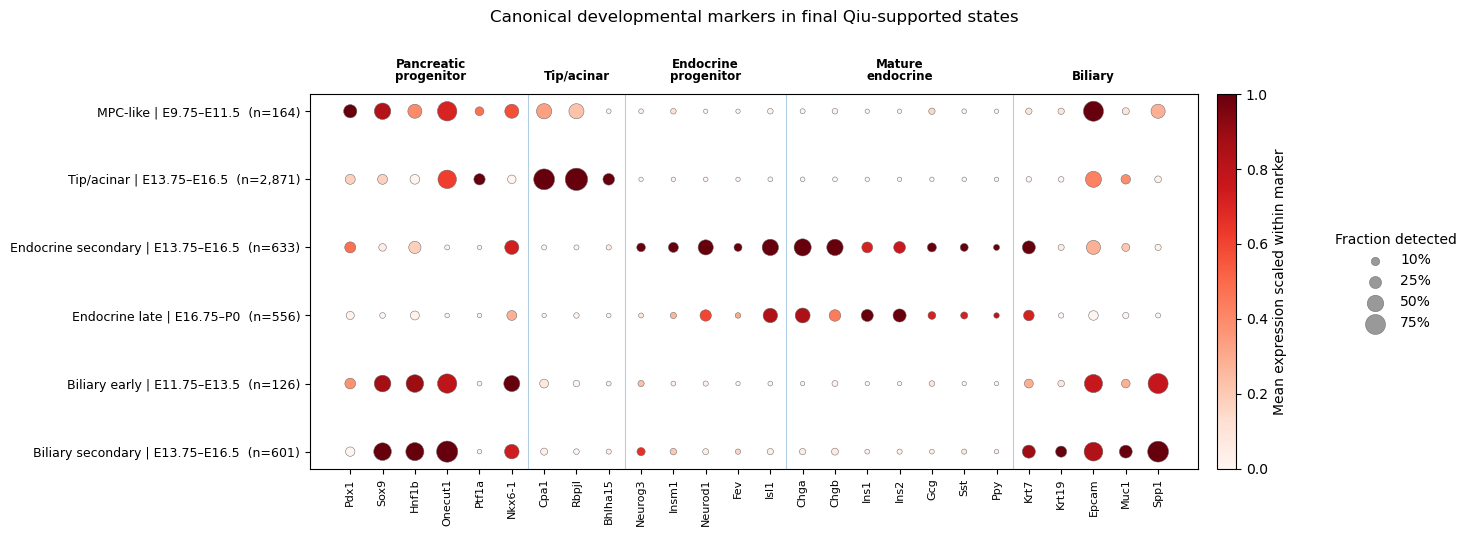

In [23]:
# ------------------------------------------------------------
# 7. Plot
# ------------------------------------------------------------

# Choose:
#   "symbol" -> best for manuscript
#   "both"   -> useful for notebook/audit
LABEL_MODE = "symbol"


if LABEL_MODE == "symbol":
    marker_df["label"] = marker_df["symbol"]

elif LABEL_MODE == "both":
    marker_df["label"] = (
        marker_df["symbol"] +
        "\n" +
        marker_df["ensembl"]
    )

else:
    raise ValueError("LABEL_MODE must be 'symbol' or 'both'")


marker_df["x"] = np.arange(len(marker_df))

key_to_x = {
    (r.program, r.symbol): r.x
    for r in marker_df.itertuples()
}

dot_df["x"] = [
    key_to_x[(p, g)]
    for p, g in zip(
        dot_df["program"],
        dot_df["symbol"]
    )
]

state_to_y = {
    s: i
    for i, s in enumerate(STATE_ORDER)
}

dot_df["y"] = dot_df["state"].map(state_to_y)


# Nice state labels including stage and n
pretty_state = {}

for state in STATE_ORDER:

    r = state_summary.loc[state]

    if state == "MPC_like":
        label = "MPC-like | E9.75–E11.5"

    elif state == "tip_acinar":
        label = "Tip/acinar | E13.75–E16.5"

    elif state == "endocrine_secondary":
        label = "Endocrine secondary | E13.75–E16.5"

    elif state == "endocrine_late":
        label = "Endocrine late | E16.75–P0"

    elif state == "biliary_early":
        label = "Biliary early | E11.75–E13.5"

    elif state == "biliary_secondary":
        label = "Biliary secondary | E13.75–E16.5"

    pretty_state[state] = (
        f"{label}  (n={int(r['n_cells']):,})"
    )


# Slightly wider figure to give the program headers room
fig, ax = plt.subplots(
    figsize=(max(15, 0.55 * len(marker_df)), 6)
)

sizes = 10 + 260 * dot_df["fraction_detected"].to_numpy()

scat = ax.scatter(
    dot_df["x"],
    dot_df["y"],
    s=sizes,
    c=dot_df["scaled_mean"],
    cmap="Reds",
    vmin=0,
    vmax=1,
    edgecolors="0.4",
    linewidths=0.35
)


# y axis
ax.set_yticks(range(len(STATE_ORDER)))
ax.set_yticklabels(
    [pretty_state[s] for s in STATE_ORDER],
    fontsize=9
)
ax.invert_yaxis()


# x axis
ax.set_xticks(marker_df["x"])
ax.set_xticklabels(
    marker_df["label"],
    rotation=90,
    fontsize=8
)


# ------------------------------------------------------------
# Program blocks
# ------------------------------------------------------------

ranges = (
    marker_df
    .groupby("program", sort=False)["x"]
    .agg(["min", "max"])
)

# Shorter display labels to avoid overlap
program_display = {
    "Pancreatic progenitor": "Pancreatic\nprogenitor",
    "Tip/acinar": "Tip/acinar",
    "Endocrine progenitor": "Endocrine\nprogenitor",
    "Mature endocrine": "Mature\nendocrine",
    "Biliary": "Biliary",
}

for i, (program, rr) in enumerate(ranges.iterrows()):

    midpoint = (rr["min"] + rr["max"]) / 2

    # Position relative to axes:
    # y=1.03 means slightly above the plotting area
    ax.text(
        midpoint,
        1.03,
        program_display.get(program, program),
        transform=ax.get_xaxis_transform(),
        ha="center",
        va="bottom",
        fontweight="bold",
        fontsize=8.5,
        linespacing=0.9,
        clip_on=False
    )

    if i > 0:
        ax.axvline(
            rr["min"] - 0.5,
            linewidth=0.8,
            alpha=0.35
        )


# Main title above program-block labels
ax.set_title(
    "Canonical developmental markers in final Qiu-supported states",
    pad=52,
    fontsize=12
)

ax.set_xlabel("")
ax.set_ylabel("")


# ------------------------------------------------------------
# Color bar
# ------------------------------------------------------------

cbar = fig.colorbar(
    scat,
    ax=ax,
    pad=0.02,
    fraction=0.035
)

cbar.set_label(
    "Mean expression scaled within marker"
)


# ------------------------------------------------------------
# Dot-size legend
# ------------------------------------------------------------

for frac in [0.10, 0.25, 0.50, 0.75]:
    ax.scatter(
        [],
        [],
        s=10 + 260 * frac,
        c="0.6",
        edgecolors="0.4",
        linewidths=0.35,
        label=f"{int(frac * 100)}%"
    )

ax.legend(
    title="Fraction detected",
    frameon=False,
    bbox_to_anchor=(1.14, 0.50),
    loc="center left"
)


# Leave explicit room at the top for headers + title
plt.tight_layout(rect=[0, 0, 1, 0.91])

plt.show()

## 6. Final Qiu-supported state definitions

The exploratory AE3 state-resolution notebook showed that the Qiu `Pancreatic acinar cells` annotation contains a strong temporal transition: early cells retain a mixed pancreatic-regulatory profile, while later cells are strongly tip/acinar. `Pancreatic islets` provide the endocrine comparison.

The final definitions below therefore use annotation **and developmental time**. A trunk/ductal vector is deliberately absent. `MPC_like → endocrine_secondary` is treated as an **endpoint contrast**, not as a literal lineage edge.


In [24]:

ct = dev_obs["celltype_update"].astype(str)
day = dev_obs["dev_day"].astype(float)

state_masks = {
    # Early pancreas-lineage / MPC-like state
    "MPC_like": ((ct == "Pancreatic acinar cells") & (day <= 11.5)),

    # Strong tip/acinar secondary-transition state
    "tip_acinar": ((ct == "Pancreatic acinar cells") & (day >= 13.75) & (day <= 16.5)),

    # Endocrine/islet secondary-transition endpoint
    "endocrine_secondary": ((ct == "Pancreatic islets") & (day >= 13.75) & (day <= 16.5)),

    # Later endocrine/islet state
    "endocrine_late": ((ct == "Pancreatic islets") & (day >= 16.75)),

    # Separate hepatobiliary maturation comparison
    "biliary_early": ((ct == "Biliary epithelial cells") & (day >= 11.75) & (day <= 13.5)),

    "biliary_secondary": ((ct == "Biliary epithelial cells") & (day >= 13.75) & (day <= 16.5)),
}

state_count_rows = []
for name, m in state_masks.items():
    dd = dev_obs.loc[m, "dev_day"]
    state_count_rows.append({
        "state": name,
        "n_cells": int(m.sum()),
        "min_day": float(dd.min()) if len(dd) else np.nan,
        "median_day": float(dd.median()) if len(dd) else np.nan,
        "max_day": float(dd.max()) if len(dd) else np.nan,
        "n_distinct_days": int(dd.nunique()),
    })

state_counts = pd.DataFrame(state_count_rows)
display(state_counts)

assert all(m.sum() >= 30 for m in state_masks.values()), (
    "One revised state has <30 cells. Inspect before continuing."
)


,state,n_cells,min_day,median_day,max_day,n_distinct_days
0,MPC_like,164,9.75,11.25,11.5,7
1,tip_acinar,2871,13.75,15.75,16.5,12
2,endocrine_secondary,633,13.75,15.50,16.5,12
3,endocrine_late,556,16.75,20.00,20.0,10
4,biliary_early,126,11.75,12.75,13.5,8
5,biliary_secondary,601,13.75,15.50,16.5,12


previous figure more explicit

## 7. Developmental PCA and revised biological directions

In [25]:
K = 75

# Preserve the original Results_Section2 reference construction here:
# center on all developmental cells, fit PCA on all developmental cells.
mu = X_dev.mean(axis=0)
Xd = X_dev - mu
Xc = X_can - mu

pca = PCA(n_components=K)
Xd_pca = pca.fit_transform(Xd)
Xc_pca = pca.transform(Xc)
basis = pca.components_.T

print("Variance explained by first", K, "developmental PCs:",
      pca.explained_variance_ratio_.sum())


Variance explained by first 75 developmental PCs: 0.97995746


In [26]:
# Cell-weighted centroids
C = {name: state_centroid(Xd_pca, mask)
     for name, mask in state_masks.items()}

# Revised biologically defensible directions.
vectors = {
    "MPC_to_tip_acinar":
        C["tip_acinar"] - C["MPC_like"],

    # Endpoint contrast — NOT a literal MPC→endocrine lineage edge.
    "MPC_to_endocrine_islet":
        C["endocrine_secondary"] - C["MPC_like"],

    # Within-endocrine maturation.
    "endocrine_maturation":
        C["endocrine_late"] - C["endocrine_secondary"],

    # Separate hepatobiliary comparison.
    "biliary_maturation":
        C["biliary_secondary"] - C["biliary_early"],
}

print("Direction norms:")
for k, v in vectors.items():
    print(f"{k:28s} {np.linalg.norm(v):.4f}")


Direction norms:
MPC_to_tip_acinar            8.4340
MPC_to_endocrine_islet       13.6837
endocrine_maturation         4.1858
biliary_maturation           3.8359


### Developmental-direction angles

In [27]:
dir_names = list(vectors)

angle_mat = pd.DataFrame(np.eye(len(dir_names)),index=dir_names,columns=dir_names,dtype=float)

for a in dir_names:
    for b in dir_names:
        angle_mat.loc[a, b] = angle_deg(vectors[a], vectors[b])

display(angle_mat.round(2))


,MPC_to_tip_acinar,MPC_to_endocrine_islet,endocrine_maturation,biliary_maturation
MPC_to_tip_acinar,0.00,74.21,77.72,94.52
MPC_to_endocrine_islet,74.21,0.00,103.52,76.41
endocrine_maturation,77.72,103.52,0.00,94.88
biliary_maturation,94.52,76.41,94.88,0.00


## 8. Malignant early / late / total displacement alignment

In [28]:

labels_can = can_obs["cancer_state"].astype(str).to_numpy()

required_states = {"ductal", "transitional", "malignant_ductal"}
missing = required_states - set(labels_can)
assert not missing, f"Missing cancer states: {missing}"

cancer_transitions = [
    ("ductal", "transitional", "early"),
    ("transitional", "malignant_ductal", "late"),
    ("ductal", "malignant_ductal", "total"),
]

malignant_vectors = {}
rows = []

for s1, s2, label in cancer_transitions:
    v = (
        centroid_value(Xc_pca, labels_can, s2)
        - centroid_value(Xc_pca, labels_can, s1)
    )
    malignant_vectors[label] = v

    row = {
        "transition": label,
        "from": s1,
        "to": s2,
        "norm": np.linalg.norm(v),
    }
    for dname, dvec in vectors.items():
        row[dname] = cos_sim(v, dvec)
    rows.append(row)

alignment = pd.DataFrame(rows)
display(alignment.round(4))


,transition,from,to,norm,MPC_to_tip_acinar,MPC_to_endocrine_islet,endocrine_maturation,biliary_maturation
0,early,ductal,transitional,7.2885,-0.3195,0.0557,-0.2094,0.2132
1,late,transitional,malignant_ductal,4.3109,-0.1263,0.0031,0.0119,-0.0591
2,total,ductal,malignant_ductal,7.6133,-0.3774,0.0551,-0.1937,0.1707


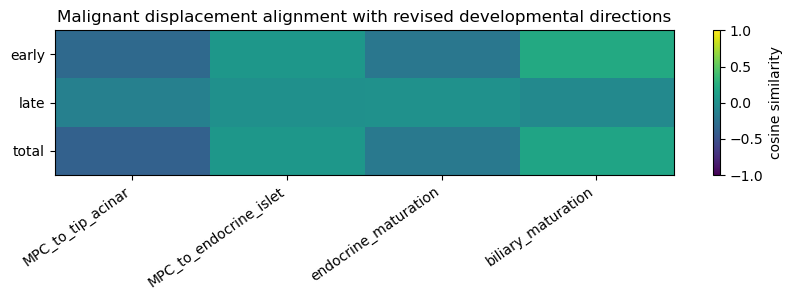

In [29]:

# Compact heatmap without assigning colors manually.
plot_df = alignment.set_index("transition")[dir_names]

fig, ax = plt.subplots(figsize=(8.5, 3.1))
im = ax.imshow(plot_df.values, aspect="auto", vmin=-1, vmax=1)
ax.set_xticks(range(len(dir_names)))
ax.set_xticklabels(dir_names, rotation=35, ha="right")
ax.set_yticks(range(plot_df.shape[0]))
ax.set_yticklabels(plot_df.index)
ax.set_title("Malignant displacement alignment with revised developmental directions")
fig.colorbar(im, ax=ax, label="cosine similarity")
plt.tight_layout()
plt.show()


## 9. Direct endocrine-positioning check for the transitional malignant state

This is a positional test, distinct from directional alignment. It asks whether the transitional centroid is preferentially close to endocrine developmental states in the current reference. The result should be used to calibrate any “neuroendocrine-like” wording rather than inferred from a few markers alone.


In [30]:

dev_compare_states = [
    "MPC_like",
    "tip_acinar",
    "endocrine_secondary",
    "endocrine_late",
    "biliary_early",
    "biliary_secondary",
]

cancer_compare_states = ["ductal", "transitional", "malignant_ductal"]

dist_rows = []
for cs in cancer_compare_states:
    cc = centroid_value(Xc_pca, labels_can, cs)
    row = {"cancer_state": cs}
    for ds in dev_compare_states:
        row[ds] = np.linalg.norm(cc - C[ds])
    dist_rows.append(row)

centroid_distances = pd.DataFrame(dist_rows).set_index("cancer_state")
display(centroid_distances.round(3))

# Within each cancer state, rank the developmental centroids by distance.
distance_ranks = centroid_distances.rank(axis=1, method="min")
display(distance_ranks.astype(int))


,MPC_like,tip_acinar,endocrine_secondary,endocrine_late,biliary_early,biliary_secondary
cancer_state,,,,,,
ductal,12.183,10.777,13.359,12.591,12.479,12.368
transitional,12.264,12.546,13.012,12.735,11.865,11.229
malignant_ductal,12.910,13.522,13.609,13.328,12.712,12.201


,MPC_like,tip_acinar,endocrine_secondary,endocrine_late,biliary_early,biliary_secondary
cancer_state,,,,,,
ductal,2,1,6,5,4,3
transitional,3,4,6,5,2,1
malignant_ductal,3,5,6,4,2,1


## 10. Primary abundance-aware directions: equal weight to developmental days

For the **final directional point estimates**, each represented developmental day contributes equally to each state centroid. This avoids allowing densely sampled days to dominate a direction simply because the whole-embryo atlas contains more cells there.

The original cell-weighted centroids remain a sensitivity analysis; the stronger equal-lineage×stage weighted PCA below is an additional robustness control.


In [31]:
C_day = {}
day_audit = []

for name, mask in state_masks.items():
    c, used, omitted = equal_day_centroid(
        Xd_pca, dev_obs, mask,
        day_col="dev_day",
        min_day_n=3
    )
    C_day[name] = c
    day_audit.append({
        "state": name,
        "n_days_used": len(used),
        "days_used": used,
        "days_omitted": omitted,
    })

day_audit = pd.DataFrame(day_audit)
display(day_audit)

vectors_day = {
    "MPC_to_tip_acinar":
        C_day["tip_acinar"] - C_day["MPC_like"],
    "MPC_to_endocrine_islet":
        C_day["endocrine_secondary"] - C_day["MPC_like"],
    "endocrine_maturation":
        C_day["endocrine_late"] - C_day["endocrine_secondary"],
    "biliary_maturation":
        C_day["biliary_secondary"] - C_day["biliary_early"],
}

rows = []
for label, mv in malignant_vectors.items():
    row = {"transition": label}
    for dname, dvec in vectors_day.items():
        row[dname] = cos_sim(mv, dvec)
    rows.append(row)

alignment_equal_day = pd.DataFrame(rows)
display(alignment_equal_day.round(4))


,state,n_days_used,days_used,days_omitted
0,MPC_like,7,"[(9.75, 4), (10.0, 4), (10.5, 9), (10.75, 27),...",[]
1,tip_acinar,12,"[(13.75, 15), (14.0, 39), (14.25, 56), (14.333...",[]
2,endocrine_secondary,11,"[(14.0, 33), (14.25, 27), (14.333, 53), (14.75...","[(13.75, 2)]"
3,endocrine_late,10,"[(16.75, 56), (17.0, 20), (17.25, 11), (17.5, ...",[]
4,biliary_early,8,"[(11.75, 7), (12.0, 7), (12.25, 4), (12.5, 15)...",[]
5,biliary_secondary,12,"[(13.75, 10), (14.0, 27), (14.25, 45), (14.333...",[]


,transition,MPC_to_tip_acinar,MPC_to_endocrine_islet,endocrine_maturation,biliary_maturation
0,early,-0.2967,0.0719,-0.2198,0.2077
1,late,-0.1342,-0.0064,0.0103,-0.1172
2,total,-0.3600,0.0653,-0.2045,0.1324


In [32]:

# Side-by-side change caused only by equal-day weighting.
primary_long = alignment.melt(
    id_vars=["transition", "from", "to", "norm"],
    value_vars=dir_names,
    var_name="developmental_direction",
    value_name="cosine_cell_weighted"
)

day_long = alignment_equal_day.melt(
    id_vars=["transition"],
    value_vars=dir_names,
    var_name="developmental_direction",
    value_name="cosine_equal_day"
)

weighting_compare = primary_long.merge(
    day_long,
    on=["transition", "developmental_direction"]
)
weighting_compare["delta"] = (
    weighting_compare["cosine_equal_day"]
    - weighting_compare["cosine_cell_weighted"]
)

display(weighting_compare.round(4))


,transition,from,to,norm,developmental_direction,cosine_cell_weighted,cosine_equal_day,delta
0,early,ductal,transitional,7.2885,MPC_to_tip_acinar,-0.3195,-0.2967,0.0227
1,late,transitional,malignant_ductal,4.3109,MPC_to_tip_acinar,-0.1263,-0.1342,-0.0079
2,total,ductal,malignant_ductal,7.6133,MPC_to_tip_acinar,-0.3774,-0.3600,0.0173
3,early,ductal,transitional,7.2885,MPC_to_endocrine_islet,0.0557,0.0719,0.0162
4,late,transitional,malignant_ductal,4.3109,MPC_to_endocrine_islet,0.0031,-0.0064,-0.0094
5,total,ductal,malignant_ductal,7.6133,MPC_to_endocrine_islet,0.0551,0.0653,0.0102
6,early,ductal,transitional,7.2885,endocrine_maturation,-0.2094,-0.2198,-0.0103
7,late,transitional,malignant_ductal,4.3109,endocrine_maturation,0.0119,0.0103,-0.0016
8,total,ductal,malignant_ductal,7.6133,endocrine_maturation,-0.1937,-0.2045,-0.0108
9,early,ductal,transitional,7.2885,biliary_maturation,0.2132,0.2077,-0.0055


## 11. Stronger lineage × stage sensitivity: equal-stratum weighted developmental PCA

In [33]:

def phase_from_day(x):
    x = float(x)
    if x <= 11.5:
        return "E8.5-E11.5"
    elif x <= 13.5:
        return "E11.75-E13.5"
    elif x <= 16.5:
        return "E13.75-E16.5"
    else:
        return "E16.75-P0"

balance_meta = dev_obs.copy()
balance_meta["balance_phase"] = balance_meta["dev_day"].map(phase_from_day)
balance_meta["balance_lineage"] = balance_meta["endo_category"].astype(str)
balance_meta["balance_stratum"] = (
    balance_meta["balance_lineage"] + " | " + balance_meta["balance_phase"]
)

stratum_counts = balance_meta["balance_stratum"].value_counts().sort_index()
display(stratum_counts.to_frame("n_cells"))

# Equal total weight per stratum.
n_strata = len(stratum_counts)
w = np.zeros(len(balance_meta), dtype=float)

for stratum, n in stratum_counts.items():
    idx = (balance_meta["balance_stratum"].to_numpy() == stratum)
    w[idx] = 1.0 / (n_strata * n)

print("weight sum:", w.sum())
print("number of strata:", n_strata)
print("smallest stratum:", int(stratum_counts.min()))
print("largest stratum:", int(stratum_counts.max()))


,n_cells
balance_stratum,
biliary | E11.75-E13.5,126
biliary | E13.75-E16.5,601
biliary | E16.75-P0,998
biliary | E8.5-E11.5,17
foregut_other | E11.75-E13.5,219
foregut_other | E13.75-E16.5,960
foregut_other | E16.75-P0,2664
foregut_other | E8.5-E11.5,105
gut_epithelium_distal | E11.75-E13.5,57


weight sum: 1.0
number of strata: 38
smallest stratum: 3
largest stratum: 3988


In [34]:
def weighted_pca_basis(X, weights, n_components):
    X = np.asarray(X, dtype=float)
    weights = np.asarray(weights, dtype=float)
    weights = weights / weights.sum()

    mu_w = np.sum(X * weights[:, None], axis=0)
    Xc = X - mu_w

    # Equal-stratum weighted covariance.
    Xw = Xc * np.sqrt(weights[:, None])
    cov = Xw.T @ Xw

    eigvals, eigvecs = np.linalg.eigh(cov)
    order = np.argsort(eigvals)[::-1]

    eigvals = eigvals[order]
    eigvecs = eigvecs[:, order]

    basis = eigvecs[:, :n_components]
    explained = eigvals[:n_components].sum() / (eigvals.sum() + 1e-12)

    return mu_w, basis, eigvals, explained

mu_bal, basis_bal, eigvals_bal, explained_bal = weighted_pca_basis(
    X_dev, w, K
)

Xd_bal = (X_dev - mu_bal) @ basis_bal
Xc_bal = (X_can - mu_bal) @ basis_bal

print("Equal-stratum weighted PCA variance fraction in first", K,
      "components:", explained_bal)


Equal-stratum weighted PCA variance fraction in first 75 components: 0.9794028975661073


In [35]:

# Use equal-day centroids again inside the abundance-balanced PCA.
C_bal = {}
for name, mask in state_masks.items():
    c, _, _ = equal_day_centroid(
        Xd_bal, dev_obs, mask,
        day_col="dev_day",
        min_day_n=3
    )
    C_bal[name] = c

vectors_bal = {
    "MPC_to_tip_acinar":
        C_bal["tip_acinar"] - C_bal["MPC_like"],
    "MPC_to_endocrine_islet":
        C_bal["endocrine_secondary"] - C_bal["MPC_like"],
    "endocrine_maturation":
        C_bal["endocrine_late"] - C_bal["endocrine_secondary"],
    "biliary_maturation":
        C_bal["biliary_secondary"] - C_bal["biliary_early"],
}

malignant_vectors_bal = {}
rows = []

for s1, s2, label in cancer_transitions:
    mv = (
        centroid_value(Xc_bal, labels_can, s2)
        - centroid_value(Xc_bal, labels_can, s1)
    )
    malignant_vectors_bal[label] = mv

    row = {"transition": label}
    for dname, dvec in vectors_bal.items():
        row[dname] = cos_sim(mv, dvec)
    rows.append(row)

alignment_balanced_pca = pd.DataFrame(rows)
display(alignment_balanced_pca.round(4))


,transition,MPC_to_tip_acinar,MPC_to_endocrine_islet,endocrine_maturation,biliary_maturation
0,early,-0.2949,0.0773,-0.2255,0.2108
1,late,-0.1335,-0.0049,0.0100,-0.1119
2,total,-0.3580,0.0710,-0.2096,0.1371


### Compare the three developmental-reference constructions

In [36]:

def tidy_alignment(df, label):
    out = df.melt(
        id_vars=["transition"],
        value_vars=dir_names,
        var_name="developmental_direction",
        value_name="cosine"
    )
    out["reference_construction"] = label
    return out

a1 = tidy_alignment(
    alignment[["transition"] + dir_names],
    "original_PCA_cell_weighted_centroids"
)
a2 = tidy_alignment(
    alignment_equal_day[["transition"] + dir_names],
    "original_PCA_equal_day_centroids"
)
a3 = tidy_alignment(
    alignment_balanced_pca[["transition"] + dir_names],
    "equal_lineage_stage_PCA_equal_day_centroids"
)

alignment_robustness = pd.concat([a1, a2, a3], ignore_index=True)
display(alignment_robustness.round(4))


,transition,developmental_direction,cosine,reference_construction
0,early,MPC_to_tip_acinar,-0.3195,original_PCA_cell_weighted_centroids
1,late,MPC_to_tip_acinar,-0.1263,original_PCA_cell_weighted_centroids
2,total,MPC_to_tip_acinar,-0.3774,original_PCA_cell_weighted_centroids
3,early,MPC_to_endocrine_islet,0.0557,original_PCA_cell_weighted_centroids
4,late,MPC_to_endocrine_islet,0.0031,original_PCA_cell_weighted_centroids
5,total,MPC_to_endocrine_islet,0.0551,original_PCA_cell_weighted_centroids
6,early,endocrine_maturation,-0.2094,original_PCA_cell_weighted_centroids
7,late,endocrine_maturation,0.0119,original_PCA_cell_weighted_centroids
8,total,endocrine_maturation,-0.1937,original_PCA_cell_weighted_centroids
9,early,biliary_maturation,0.2132,original_PCA_cell_weighted_centroids


## 12. Developmental-reference resampling

In [37]:
RNG = np.random.default_rng(13)
N_BOOT = 500
MIN_DAY_N = 3
MAX_PER_DAY = 50

def balanced_day_sample_centroid(X, obs, mask, rng,
                                 day_col="dev_day",
                                 min_day_n=3,
                                 max_per_day=50):
    mask = np.asarray(mask, dtype=bool)
    days = sorted(pd.unique(obs.loc[mask, day_col].dropna()))

    pools = []
    for d in days:
        idx = np.flatnonzero(mask & (obs[day_col].to_numpy() == d))
        if len(idx) >= min_day_n:
            pools.append(idx)

    if not pools:
        raise ValueError("No eligible day pools.")

    n_draw = min(max_per_day, min(len(x) for x in pools))
    selected = np.concatenate([
        rng.choice(idx, size=n_draw, replace=False)
        for idx in pools
    ])
    return np.asarray(X)[selected].mean(axis=0)

boot_rows = []

for b in range(N_BOOT):
    cb = {
        name: balanced_day_sample_centroid(
            Xd_bal, dev_obs, mask, RNG,
            min_day_n=MIN_DAY_N,
            max_per_day=MAX_PER_DAY
        )
        for name, mask in state_masks.items()
    }

    vb = {
        "MPC_to_tip_acinar":
            cb["tip_acinar"] - cb["MPC_like"],
        "MPC_to_endocrine_islet":
            cb["endocrine_secondary"] - cb["MPC_like"],
        "endocrine_maturation":
            cb["endocrine_late"] - cb["endocrine_secondary"],
        "biliary_maturation":
            cb["biliary_secondary"] - cb["biliary_early"],
    }

    for trans, mv in malignant_vectors_bal.items():
        for dname, dvec in vb.items():
            boot_rows.append({
                "bootstrap": b,
                "transition": trans,
                "developmental_direction": dname,
                "cosine": cos_sim(mv, dvec),
            })

boot = pd.DataFrame(boot_rows)

boot_summary = (
    boot.groupby(["transition", "developmental_direction"], observed=True)["cosine"]
        .agg(
            median="median",
            lo=lambda x: np.quantile(x, 0.025),
            hi=lambda x: np.quantile(x, 0.975),
        )
        .reset_index()
)

display(boot_summary.round(4))


,transition,developmental_direction,median,lo,hi
0,early,MPC_to_endocrine_islet,0.0774,0.0537,0.1022
1,early,MPC_to_tip_acinar,-0.2927,-0.3297,-0.2503
2,early,biliary_maturation,0.1979,0.0862,0.2732
3,early,endocrine_maturation,-0.2141,-0.2650,-0.1412
4,late,MPC_to_endocrine_islet,-0.0045,-0.0198,0.0115
5,late,MPC_to_tip_acinar,-0.1314,-0.1623,-0.0984
6,late,biliary_maturation,-0.1065,-0.1677,-0.0483
7,late,endocrine_maturation,0.0073,-0.0328,0.0548
8,total,MPC_to_endocrine_islet,0.0714,0.0476,0.0946
9,total,MPC_to_tip_acinar,-0.3537,-0.3871,-0.3147


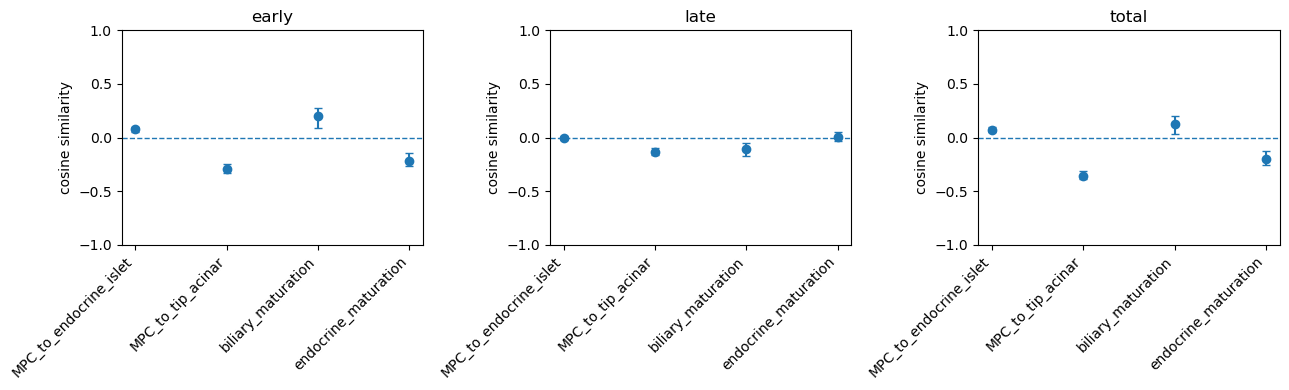

In [38]:

# One figure: bootstrap intervals for each malignant transition.
fig, axes = plt.subplots(1, len(cancer_transitions),figsize=(13, 4),sharex=True)

if len(cancer_transitions) == 1:
    axes = [axes]

for ax, (_, _, trans) in zip(axes, cancer_transitions):
    sub = boot_summary[boot_summary["transition"] == trans].copy()
    x = np.arange(len(sub))

    med = sub["median"].to_numpy()
    lo = sub["lo"].to_numpy()
    hi = sub["hi"].to_numpy()

    ax.errorbar(
        x, med,
        yerr=np.vstack([med - lo, hi - med]),
        fmt="o",
        capsize=3
    )
    ax.axhline(0, linestyle="--", linewidth=1)
    ax.set_xticks(x)
    ax.set_xticklabels(
        sub["developmental_direction"],
        rotation=45,
        ha="right"
    )
    ax.set_ylim(-1, 1)
    ax.set_title(trans)
    ax.set_ylabel("cosine similarity")

plt.tight_layout()
plt.show()


## 13. Biological-sample uncertainty and random-direction nulls for the revised axes

AE2's bootstrap/null machinery was valid but used the superseded three-axis biological definitions. This section regenerates the inferential context using the **final equal-day Qiu-supported directions**.

- Burdziak `batch` is the biological-sample unit.
- Samples are resampled first; cells are resampled within selected samples.
- Developmental directions are held fixed in this sample bootstrap because developmental-reference uncertainty is quantified separately by the balanced developmental resampling above.
- A random-direction benchmark gives the expected maximum absolute cosine to the same four revised developmental directions in the K-dimensional developmental-PC space.


In [ ]:
# ============================================================
# 13. Biological-sample uncertainty and random-direction nulls
#     for the revised axes
# ============================================================ƒ

PRIMARY_DEV_DIRECTIONS = vectors_day
PRIMARY_CANCER_COORDS = np.asarray(Xc_pca)
PRIMARY_DIRECTION_NAMES = list(PRIMARY_DEV_DIRECTIONS)

SAMPLE_COL = "batch"
STATE_ORDER = ["ductal", "transitional", "malignant_ductal"]

if SAMPLE_COL not in can_obs.columns:
    raise KeyError(
        f"{SAMPLE_COL!r} is required for sample-level AE3 inference."
    )

# ------------------------------------------------------------
# IMPORTANT:
# Make an explicit row-position column.
#
# This avoids relying on index-name -> integer-position mapping
# inside grouped subsets and prevents empty categorical groups
# from generating empty-slice means.
# ------------------------------------------------------------

boot_obs = can_obs.copy()
boot_obs["_row_position"] = np.arange(len(boot_obs))


def _sample_groups_for_state(obs, state):
    """
    Return only OBSERVED biological-sample groups for one cancer state.

    observed=True is important because SAMPLE_COL may be categorical:
    unused categorical sample levels must not become empty groups.
    """
    sub = obs.loc[
        obs["cancer_state"].astype(str).eq(state)
    ]

    return sub.groupby(
        SAMPLE_COL,
        observed=True,
        sort=False
    )


def precompute_sample_boot_centroids(
    X,
    obs,
    n_inner=200,
    seed=13
):
    """
    For each cancer state and biological sample, generate bootstrap
    cell-level centroids.

    Outer bootstrap later resamples biological samples.
    """
    rr = np.random.default_rng(seed)
    X = np.asarray(X)

    out = {}

    for state in STATE_ORDER:

        out[state] = {}

        for sample, group in _sample_groups_for_state(obs, state):

            pos = group["_row_position"].to_numpy(dtype=int)

            if pos.size == 0:
                continue

            Xi = X[pos]

            B = np.empty(
                (n_inner, Xi.shape[1]),
                dtype=np.float32
            )

            for b in range(n_inner):

                draw = rr.integers(
                    0,
                    Xi.shape[0],
                    size=Xi.shape[0]
                )

                B[b] = Xi[draw].mean(axis=0)

            out[state][str(sample)] = B

    return out


def sample_equal_state_centroids(X, obs):
    """
    Observed cancer-state centroids with equal weight assigned
    to each biological sample within a state.

    Each sample contributes one sample mean, irrespective of
    its number of cells.
    """
    X = np.asarray(X)

    C = {}

    for state in STATE_ORDER:

        sample_means = []

        for sample, group in _sample_groups_for_state(obs, state):

            pos = group["_row_position"].to_numpy(dtype=int)

            if pos.size == 0:
                continue

            sample_mean = X[pos].mean(axis=0)

            # Defensive check: no non-finite centroid should enter
            if not np.all(np.isfinite(sample_mean)):
                raise ValueError(
                    f"Non-finite sample centroid for "
                    f"state={state!r}, sample={sample!r}"
                )

            sample_means.append(sample_mean)

        if len(sample_means) == 0:
            raise ValueError(
                f"No observed biological samples found "
                f"for cancer state {state!r}"
            )

        C[state] = np.mean(
            np.stack(sample_means),
            axis=0
        )

    return C


# ------------------------------------------------------------
# Precompute within-sample cell bootstraps
# ------------------------------------------------------------

inner = precompute_sample_boot_centroids(
    PRIMARY_CANCER_COORDS,
    boot_obs,
    n_inner=200,
    seed=13
)

sample_lists = {
    state: sorted(inner[state].keys())
    for state in STATE_ORDER
}

print(
    "Biological samples per state:",
    {k: len(v) for k, v in sample_lists.items()}
)


# Sanity check
for state in STATE_ORDER:
    if len(sample_lists[state]) == 0:
        raise ValueError(
            f"No biological samples available for {state!r}"
        )


# ============================================================
# Hierarchical biological-sample bootstrap
# ============================================================

rr = np.random.default_rng(1313)

N_OUTER = 2000

sample_boot_rows = []

for b in range(N_OUTER):

    Cb = {}

    for state, samples in sample_lists.items():

        # Sample biological samples with replacement
        picked = rr.choice(
            samples,
            size=len(samples),
            replace=True
        )

        vals = []

        for sample in picked:

            # Pick one precomputed cell-bootstrap centroid
            # for this selected biological sample
            arr = inner[state][sample]

            vals.append(
                arr[
                    rr.integers(
                        0,
                        arr.shape[0]
                    )
                ]
            )

        Cb[state] = np.mean(
            np.stack(vals),
            axis=0
        )

    # Recalculate malignant displacement vectors
    for s1, s2, trans in cancer_transitions:

        mv = Cb[s2] - Cb[s1]

        for dname, dvec in PRIMARY_DEV_DIRECTIONS.items():

            sample_boot_rows.append({
                "bootstrap": b,
                "transition": trans,
                "developmental_direction": dname,
                "cosine": cos_sim(mv, dvec),
            })


sample_boot = pd.DataFrame(sample_boot_rows)

sample_boot_summary = (
    sample_boot
    .groupby(
        ["transition", "developmental_direction"],
        observed=True
    )["cosine"]
    .agg(
        median="median",
        lo=lambda x: np.quantile(x, 0.025),
        hi=lambda x: np.quantile(x, 0.975),
    )
    .reset_index()
)

display(sample_boot_summary.round(4))


# ============================================================
# Observed equal-biological-sample-weight point estimates
# ============================================================

C_sample = sample_equal_state_centroids(
    PRIMARY_CANCER_COORDS,
    boot_obs
)

# Sanity check
for state, centroid in C_sample.items():
    print(
        state,
        "finite =", np.all(np.isfinite(centroid)),
        "norm =", np.linalg.norm(centroid)
    )


observed_sample_rows = []
observed_vectors = {}

for s1, s2, trans in cancer_transitions:

    mv = C_sample[s2] - C_sample[s1]

    observed_vectors[trans] = mv

    row = {
        "transition": trans
    }

    for dname, dvec in PRIMARY_DEV_DIRECTIONS.items():

        row[dname] = cos_sim(
            mv,
            dvec
        )

    row["max_abs_revised_dev_cosine"] = max(
        abs(row[d])
        for d in PRIMARY_DIRECTION_NAMES
    )

    observed_sample_rows.append(row)


observed_sample_alignment = pd.DataFrame(
    observed_sample_rows
)

display(
    observed_sample_alignment.round(4)
)


# Must contain no NaNs before constructing null
assert np.isfinite(
    observed_sample_alignment[
        PRIMARY_DIRECTION_NAMES +
        ["max_abs_revised_dev_cosine"]
    ].to_numpy(dtype=float)
).all(), "Observed sample-weighted alignment contains NaN/Inf."


# ============================================================
# Geometric random-direction null
#
# Random vectors are generated in the same K-dimensional
# developmental-PC space.
#
# Statistic:
# maximum |cosine| to any of the four revised developmental
# directions.
# ============================================================

A_dirs = np.column_stack([
    unit(PRIMARY_DEV_DIRECTIONS[d])
    for d in PRIMARY_DIRECTION_NAMES
])


# Sanity checks
print("Developmental-direction matrix:", A_dirs.shape)

assert A_dirs.shape[0] == K
assert np.all(np.isfinite(A_dirs))


rr = np.random.default_rng(2026)

N_RANDOM_DIRECTIONS = 100_000

R = rr.normal(
    size=(N_RANDOM_DIRECTIONS, K)
)

R /= (
    np.linalg.norm(
        R,
        axis=1,
        keepdims=True
    ) + 1e-12
)


null_cos = R @ A_dirs

null_max = np.max(
    np.abs(null_cos),
    axis=1
)


# ============================================================
# Compare observed malignant direction with null
# ============================================================

random_direction_rows = []

for _, row in observed_sample_alignment.iterrows():

    obs_value = float(
        row["max_abs_revised_dev_cosine"]
    )

    if not np.isfinite(obs_value):
        raise ValueError(
            f"Observed statistic for "
            f"{row['transition']} is not finite."
        )

    upper_p = (
        1
        + np.sum(null_max >= obs_value)
    ) / (
        len(null_max) + 1
    )

    random_direction_rows.append({
        "transition":
            row["transition"],

        "observed_max_abs_cosine":
            obs_value,

        "null_median":
            float(np.median(null_max)),

        "null_q025":
            float(np.quantile(null_max, 0.025)),

        "null_q975":
            float(np.quantile(null_max, 0.975)),

        "percentile_of_observed":
            float(np.mean(null_max <= obs_value)),

        "upper_tail_empirical_p":
            float(upper_p),
    })


revised_random_direction_null = pd.DataFrame(
    random_direction_rows
)

display(
    revised_random_direction_null.round(4)
)

Biological samples per state: {'ductal': 4, 'transitional': 11, 'malignant_ductal': 6}


,transition,developmental_direction,median,lo,hi
0,early,MPC_to_endocrine_islet,0.0640,-0.0083,0.1434
1,early,MPC_to_tip_acinar,-0.3003,-0.3651,-0.2368
2,early,biliary_maturation,0.2413,0.0654,0.4170
3,early,endocrine_maturation,-0.1929,-0.2466,-0.0869
4,late,MPC_to_endocrine_islet,-0.0126,-0.1315,0.1122
5,late,MPC_to_tip_acinar,-0.1268,-0.1785,-0.0617
6,late,biliary_maturation,-0.1021,-0.2202,0.0234
7,late,endocrine_maturation,0.0113,-0.0703,0.0886
8,total,MPC_to_endocrine_islet,0.0503,-0.0264,0.1324
9,total,MPC_to_tip_acinar,-0.3591,-0.4261,-0.2874


ductal finite = True norm = 8.082857
transitional finite = True norm = 8.855986
malignant_ductal finite = True norm = 9.347446


,transition,MPC_to_tip_acinar,MPC_to_endocrine_islet,endocrine_maturation,biliary_maturation,max_abs_revised_dev_cosine
0,early,-0.3161,0.0652,-0.1967,0.2431,0.3161
1,late,-0.1365,-0.0161,0.0103,-0.1100,0.1365
2,total,-0.3801,0.0518,-0.1794,0.1633,0.3801


Developmental-direction matrix: (75, 4)


,transition,observed_max_abs_cosine,null_median,null_q025,null_q975,percentile_of_observed,upper_tail_empirical_p
0,early,0.3161,0.1615,0.0593,0.3106,0.9783,0.0217
1,late,0.1365,0.1615,0.0593,0.3106,0.3468,0.6532
2,total,0.3801,0.1615,0.0593,0.3106,0.9970,0.0030


## 14. Export final AE3 tables

In [ ]:
outdir = str(AE3_OUTDIR)
os.makedirs(outdir, exist_ok=True)

state_counts.to_csv(os.path.join(outdir, "ae3_final_revised_state_counts.csv"),index=False)
alignment.to_csv(os.path.join(outdir, "ae3_cellweighted_direction_alignment.csv"),index=False)
alignment_equal_day.to_csv(os.path.join(outdir, "ae3_PRIMARY_equalday_direction_alignment.csv"),index=False)
centroid_distances.to_csv(os.path.join(outdir, "ae3_cancer_to_development_centroid_distances.csv"))
alignment_robustness.to_csv(os.path.join(outdir, "ae3_reference_construction_robustness.csv"),index=False)
boot_summary.to_csv(os.path.join(outdir, "ae3_developmental_resampling_cosine_intervals.csv"),index=False)
sample_boot_summary.to_csv(os.path.join(outdir, "ae3_revised_direction_sample_bootstrap.csv"),index=False)
observed_sample_alignment.to_csv(os.path.join(outdir, "ae3_revised_direction_sample_equal_point_estimates.csv"),index=False)
revised_random_direction_null.to_csv(os.path.join(outdir, "ae3_revised_direction_random_null.csv"),index=False)

print("Saved FINAL AE3 outputs to:", outdir)


Saved FINAL WP3 outputs to: /home/jfpoyatos/Work/MNCN_24_25/Development_and_PDAC/data/revision_audited_mlm/analysis/wp3_developmental_reference_joint_seed_17


# AE3 final interpretation and closure — audited embedding

The final developmental-reference specification is unchanged biologically: early pancreatic/MPC-like, later tip/acinar, endocrine/islet maturation and hepatobiliary comparisons are defined from original Qiu annotations plus developmental time. `foregut_other` is not a pancreatic root and a trunk/ductal node is not manufactured.

What changed after AE1b is **only the numerical realization** of those definitions: developmental PCA, centroids, displacement vectors, malignant alignment, balanced-reference sensitivity, biological-sample bootstrap and geometric nulls are recalculated in the definitive clean joint representation.


